# 04: Explainability and the leakage experiment (BIDMC, Model A)

**Part A.** What does the 1D CNN look at? Grad-CAM over time, plus two sanity checks (randomised weights, occlusion).
**Part B.** How much does a random-window split inflate the CNN's accuracy compared with a patient-level split? Same model, same data, same seed; only the split changes.

This is the 1D signal CNN, not a video model.

In [1]:
import sys; sys.path.insert(0, "..")
import numpy as np, pandas as pd, wfdb, matplotlib.pyplot as plt
from breathcam import db
from breathcam.dataset import load_bidmc, subject_folds
from breathcam.eval import load_windows, bootstrap_ci, mae
from breathcam.explain import grad_cam_1d
from breathcam.models import BreathCNN
from breathcam.train import fit, predict

d = load_bidmc("../data/bidmc")
X, y, rec, t0 = d["X"], d["y"], d["rec"], d["t0"]
print(X.shape)

(4809, 750)


## Part A: what does the model attend to?

Train one model the same way as fold 1 of the cross-validation (patient-level, 10% of training patients for early stopping) and explain it on windows from the held-out patients.

In [2]:
tr, te = subject_folds(rec, 5)[0]
rng = np.random.default_rng(0)
val_p = rng.choice(np.unique(rec[tr]), max(1, len(np.unique(rec[tr])) // 10), replace=False)
is_val = np.isin(rec[tr], val_p)
model, _ = fit(X[tr[~is_val]], y[tr[~is_val]], X[tr[is_val]], y[tr[is_val]], seed=0)
print(f"held-out patients: {len(np.unique(rec[te]))}, test MAE {np.abs(predict(model, X[te]) - y[te]).mean():.2f} bpm")

sel = np.random.default_rng(1).choice(te, 300, replace=False)     # 300 held-out windows
cam = grad_cam_1d(model, X[sel])

held-out patients: 11, test MAE 0.62 bpm


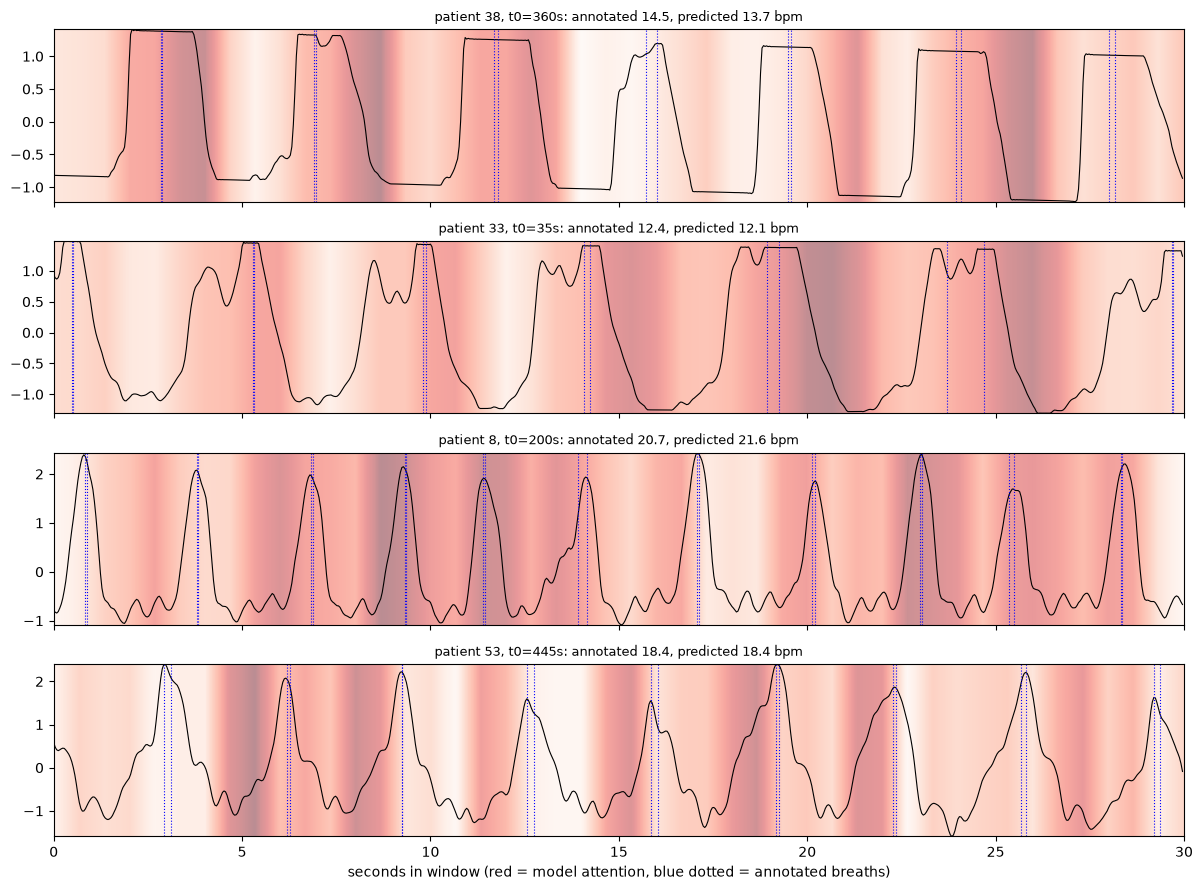

In [3]:
# annotated breaths inside each selected window, as sample indices at 25 Hz
ann = {}
def breaths(i):
    r = rec[i]
    if r not in ann:
        a = wfdb.rdann(f"../data/bidmc/bidmc{r:02d}", "breath"); ann[r] = a.sample / 125.0
    t = ann[r][(ann[r] >= t0[i]) & (ann[r] < t0[i] + 30)] - t0[i]
    return np.round(t * 25).astype(int)

fig, axes = plt.subplots(4, 1, figsize=(12, 9), sharex=True)
for ax, k in zip(axes, [0, 1, 2, 3]):
    i = sel[k]; t = np.arange(750) / 25
    ax.plot(t, X[i], "k", lw=0.8)
    ax.imshow(cam[k][None], aspect="auto", extent=[0, 30, X[i].min(), X[i].max()], cmap="Reds", alpha=0.45, vmin=0, vmax=1)
    for b in breaths(i): ax.axvline(b / 25, color="b", lw=0.8, ls=":")
    ax.set_title(f"patient {rec[i]}, t0={t0[i]:.0f}s: annotated {y[i]:.1f}, predicted {predict(model, X[i:i+1])[0]:.1f} bpm", fontsize=9)
axes[-1].set_xlabel("seconds in window (red = model attention, blue dotted = annotated breaths)")
plt.tight_layout(); plt.savefig("../docs/figures/gradcam_1d_examples.png", dpi=130)

### Quantitative check: does attention sit near the annotated breaths?

Ratio = mean attention within +/-0.5 s of annotated breaths / mean attention over the window. 1.0 means no preference. The control shifts the breath times by a random offset.

In [4]:
def ratio(c, idx, shift=0):
    idx = (idx + shift) % 750
    m = np.zeros(750, bool)
    for b in idx: m[max(0, b - 12):b + 13] = True
    return c[m].mean() / c.mean() if m.any() else np.nan

r_true, r_ctrl = [], []
shifts = np.random.default_rng(2).integers(60, 690, len(sel))
for k, i in enumerate(sel):
    b = breaths(i)
    if len(b) >= 3:
        r_true.append(ratio(cam[k], b)); r_ctrl.append(ratio(cam[k], b, shifts[k]))
print(f"{len(r_true)} windows: attention ratio at annotated breaths {np.mean(r_true):.2f}  (shifted control {np.mean(r_ctrl):.2f}); "
      f"above 1 in {np.mean(np.array(r_true) > 1):.0%} of windows (control {np.mean(np.array(r_ctrl) > 1):.0%})")

300 windows: attention ratio at annotated breaths 1.01  (shifted control 1.01); above 1 in 62% of windows (control 52%)


### Sanity check 1: randomised weights

A heatmap that comes from the learned function should differ from the heatmap of an untrained network with the same architecture.

In [5]:
torch_seed = __import__("torch").manual_seed(123)
cam_rand = grad_cam_1d(BreathCNN(), X[sel])
corr = [np.corrcoef(a, b)[0, 1] for a, b in zip(cam, cam_rand)]
print(f"mean correlation between trained and randomised-weights heatmaps: {np.nanmean(corr):.2f}")

mean correlation between trained and randomised-weights heatmaps: -0.00


### Sanity check 2: occlusion

Replace the 5 s of the window with the highest attention (or the lowest, or a random 5 s) by zero (the window mean) and measure how much the predicted rate moves.

In [6]:
def occlude(Xw, starts, L=125):
    Xo = Xw.copy()
    for k, s in enumerate(starts): Xo[k, s:s + L] = 0
    return Xo

L = 125
smooth = np.stack([np.convolve(c, np.ones(L) / L, mode="valid") for c in cam])          # attention of each 5 s span
hi, lo = smooth.argmax(1), smooth.argmin(1)
rnd = np.random.default_rng(3).integers(0, 750 - L, len(sel))
base = predict(model, X[sel])
for name, st in [("highest-attention 5 s", hi), ("random 5 s", rnd), ("lowest-attention 5 s", lo)]:
    print(f"{name:22s} mean |change in predicted rate| = {np.abs(predict(model, occlude(X[sel], st)) - base).mean():.2f} bpm")

highest-attention 5 s  mean |change in predicted rate| = 1.28 bpm


random 5 s             mean |change in predicted rate| = 1.23 bpm


lowest-attention 5 s   mean |change in predicted rate| = 1.05 bpm


## Part B: leakage

Same CNN, same seed, same epochs. (a) patient-level splits (Phase 5 predictions in `bidmc.db`); (b) random-window splits (`python -m breathcam.leakage`). Windows overlap by 25 of 30 s, so with random splits the model is tested on near-copies of what it trained on.

In [7]:
patient = load_windows(db.connect("../data/bidmc.db"))
z = np.load("../data/leakage_random.npz")
rand = pd.DataFrame(dict(subject_id=z["rec"], est_bpm=z["pred"], ref_bpm=z["y"]))
rand_mean = pd.DataFrame(dict(subject_id=z["rec"], est_bpm=z["mean"], ref_bpm=z["y"]))
rows = {
    "CNN, random split\n(leaky)": rand,
    "CNN, patient split\n(honest)": patient[patient.method == "cnn1d"],
    "Welch\n(no training)": patient[patient.method == "welch"],
    "mean-rate baseline\n(patient split)": patient[patient.method == "meanrate"],
}
res = {k: bootstrap_ci(v, mae, "subject_id") for k, v in rows.items()}
tab = pd.DataFrame(res, index=["MAE", "CI low", "CI high"]).T.round(2)
tab

,MAE,CI low,CI high
"CNN, random split\n(leaky)",0.46,0.40,0.54
"CNN, patient split\n(honest)",0.98,0.69,1.38
Welch\n(no training),1.16,0.81,1.55
mean-rate baseline\n(patient split),2.31,1.82,2.85


random-split MAE is 0.47x the patient-split MAE


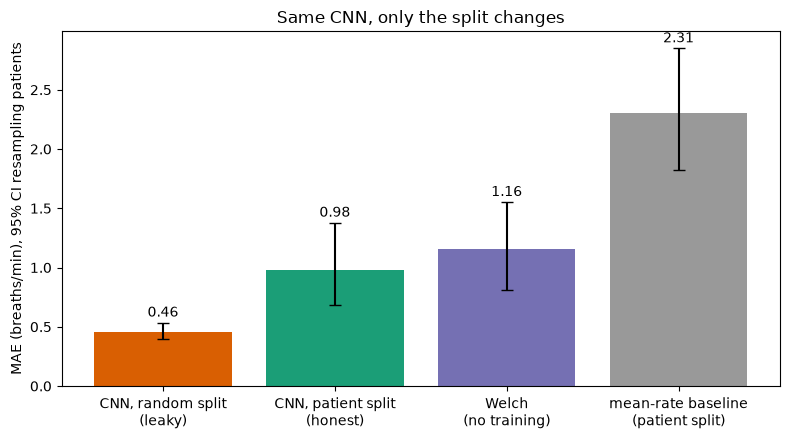

In [8]:
fig, ax = plt.subplots(figsize=(8, 4.5))
names = list(res); m = np.array([res[k][0] for k in names]); lo_, hi_ = np.array([[res[k][1], res[k][2]] for k in names]).T
ax.bar(names, m, yerr=[m - lo_, hi_ - m], capsize=4, color=["#d95f02", "#1b9e77", "#7570b3", "#999999"])
for i, v in enumerate(m): ax.text(i, hi_[i] + 0.05, f"{v:.2f}", ha="center")
ax.set_ylabel("MAE (breaths/min), 95% CI resampling patients"); ax.set_title("Same CNN, only the split changes")
plt.tight_layout(); plt.savefig("../docs/figures/leakage_random_vs_patient.png", dpi=150)
print(f"random-split MAE is {res['CNN, random split\n(leaky)'][0] / res['CNN, patient split\n(honest)'][0]:.2f}x the patient-split MAE")

## Findings

### What the model attends to (1D CNN, 11 held-out patients, test MAE 0.62)
- **Attention is not tied to the breaths.** Within +/-0.5 s of annotated breaths the attention is 1.01x the window average, the same as a shifted control (1.01x); it is above average near breaths in 62% of windows vs 52% for the control. In the example plots the attention bands are broad and spread over the whole window, on flanks and plateaus as much as at the annotated peaks. This fits how the model is built: global average pooling over time means it judges the *rhythm of the whole window*, not individual breaths.
- **Sanity check 1 (randomised weights): passed.** The heatmaps of the trained model and of an untrained network with the same architecture are uncorrelated (mean correlation 0.00), so the maps come from what the model learned, not from the architecture alone.
- **Sanity check 2 (occlusion): only weakly supportive.** Zeroing the 5 s with the highest attention moves the predicted rate by 1.28 bpm, a random 5 s by 1.23, and the lowest-attention 5 s by 1.05. The order is as expected, but the gap is about 0.2 bpm. Removing any sixth of the window disturbs the period estimate by about 1 bpm.
- **Takeaway.** The heatmaps are a plausible picture, not proof. For a model that estimates a periodic rate from the whole window, Grad-CAM is weakly informative, and the heatmaps should not be over-read. This says nothing about video: whether a video model looks at the chest (versus the face or background) needs the 3D model and video data.

### How much leakage inflates the result
- Same CNN, data, seed and epochs; only the split changes. Random-window split: **MAE 0.46** (95% CI 0.40-0.54, resampling patients). Patient-level split: **MAE 0.98** (0.69-1.38). The honest error is **2.1x** the leaky one; per-fold errors are 0.42-0.52 with random splits versus 0.53-1.60 with patient splits.
- Read at face value, the leaky number looks like the CNN beats Welch (1.16) by 2.5x; the honest comparison (Phase 5) shows the two cannot be told apart.
- Why: 30 s windows start every 5 s, so neighbouring windows share 25 s of signal, and a patient has a characteristic waveform. With random splits the test windows are near-copies of training windows, and the model is rewarded for recognising patients, not for measuring breathing.
- Caveats: one seed and one architecture; the size of the inflation depends on the window overlap and data, but the direction is the general lesson. The same applies to video: clips from one subject or session must stay on one side of the split.